# UrbanCart Growth & Marketing Analysis (Jan - Jun 2026)
### Part 1: Exploratory Data Analysis & Performance Metrics

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load raw datasets
users = pd.read_csv("../data/users.csv")
orders = pd.read_csv("../data/orders.csv")
spend = pd.read_csv("../data/marketing_spend.csv")

print(f"Users shape: {users.shape}")
print(f"Orders shape: {orders.shape}")
print(f"Marketing spend shape: {spend.shape}")

Users shape: (5135, 5)
Orders shape: (5684, 5)
Marketing spend shape: (24, 3)


### 1. Data Quality Audit & Cleaning
Identify every data issue, count affected rows, and apply fixes.

In [21]:
audit_records = []

# 1. Clean and normalize channel casing & whitespace
users['acquisition_channel'] = users['acquisition_channel'].str.strip().str.title()
spend['channel'] = spend['channel'].str.strip().str.title()

# 2. Check and handle missing/NaN acquisition_channel (Discovered from revenue reconciliation)
null_channel_count = users['acquisition_channel'].isna().sum()
users['acquisition_channel'] = users['acquisition_channel'].fillna('Unknown')
audit_records.append({
    "Table": "users.csv",
    "Issue Found": "Missing (NaN) acquisition_channel",
    "Affected Rows": int(null_channel_count),
    "Action Taken": "Imputed as 'Unknown' to prevent silent exclusion of ₹88,070 in revenue"
})

# 3. Check duplicate user IDs
dup_users = users.duplicated(subset=['user_id']).sum()
audit_records.append({
    "Table": "users.csv",
    "Issue Found": "Duplicate user_id entries",
    "Affected Rows": int(dup_users),
    "Action Taken": "Deduplicated keeping the first chronological signup instance"
})

# 4. Check non-positive order values
invalid_orders = (orders['order_value'] <= 0).sum()
audit_records.append({
    "Table": "orders.csv",
    "Issue Found": "Zero or negative order values",
    "Affected Rows": int(invalid_orders),
    "Action Taken": "Filtered out non-positive order records"
})

# 5. Check order status whitespace and casing
orders['status'] = orders['status'].str.strip().str.lower()
null_status = orders['status'].isna().sum()
audit_records.append({
    "Table": "orders.csv",
    "Issue Found": "Unstandardized casing/whitespace or missing order status",
    "Affected Rows": int(null_status),
    "Action Taken": "Trimmed strings to lowercase; dropped missing status records"
})

# 6. Parse dates
users['signup_date'] = pd.to_datetime(users['signup_date'])
users['signup_month'] = users['signup_date'].dt.to_period('M')
orders['order_date'] = pd.to_datetime(orders['order_date'])
spend['month'] = pd.to_datetime(spend['month']).dt.to_period('M')

# Clean working datasets
users_clean = users.drop_duplicates(subset=['user_id'], keep='first').copy()
orders_clean = orders[(orders['order_value'] > 0) & (orders['status'].notna())].copy()

# Display audit table for Q1
audit_df = pd.DataFrame(audit_records)
display(audit_df)

,Table,Issue Found,Affected Rows,Action Taken
0,users.csv,Missing (NaN) acquisition_channel,72,Imputed as 'Unknown' to prevent silent exclusi...
1,users.csv,Duplicate user_id entries,0,Deduplicated keeping the first chronological s...
2,orders.csv,Zero or negative order values,0,Filtered out non-positive order records
3,orders.csv,Unstandardized casing/whitespace or missing or...,0,Trimmed strings to lowercase; dropped missing ...


### 2, 3 & 4. Channel Economics: Spend, CAC, Customer Value, and LTV:CAC
Definitions:
- **New Customer**: User with $\ge 1$ delivered order under their acquisition channel.
- **CAC**: Total channel spend / new customers.
- **Revenue per customer**: Total revenue from delivered orders / new customers.
- **Repeat purchase rate**: % of customers with $\ge 2$ delivered orders.
- **LTV**: Revenue per customer * 30% contribution margin.
- **LTV:CAC**: LTV / CAC.

In [22]:
# Filter for successful delivered orders
delivered_orders = orders_clean[orders_clean['status'] == 'delivered'].copy()

# Summarize customer behavior
user_summary = delivered_orders.groupby('user_id').agg(
    delivered_orders=('order_id', 'count'),
    delivered_revenue=('order_value', 'sum')
).reset_index()

# Merge with acquisition channels
customer_df = users_clean.merge(user_summary, on='user_id', how='inner')
customer_df['is_repeat'] = customer_df['delivered_orders'] >= 2

# Channel aggregation (dropna=False preserves the 'Unknown' cohort)
channel_summary = customer_df.groupby('acquisition_channel', dropna=False).agg(
    new_customers=('user_id', 'count'),
    repeat_customers=('is_repeat', 'sum'),
    delivered_revenue=('delivered_revenue', 'sum')
).reset_index()

# Spend aggregation
spend_summary = spend.groupby('channel')['spend_inr'].sum().reset_index()
spend_summary.rename(columns={'channel': 'acquisition_channel'}, inplace=True)

# Merge performance and spend
perf_table = pd.merge(channel_summary, spend_summary, on='acquisition_channel', how='left').fillna({'spend_inr': 0})

# Compute metrics with brief's rounding rules (Money to nearest rupee, percentages to 1 decimal place)
perf_table['spend_inr'] = perf_table['spend_inr'].round(0).astype(int)
perf_table['cac'] = np.where(
    perf_table['new_customers'] > 0,
    np.round(perf_table['spend_inr'] / perf_table['new_customers']),
    0
).astype(int)

perf_table['rev_per_customer'] = np.round(perf_table['delivered_revenue'] / perf_table['new_customers']).astype(int)
perf_table['repeat_rate_pct'] = np.round((perf_table['repeat_customers'] / perf_table['new_customers']) * 100, 1)
perf_table['ltv'] = np.round(perf_table['rev_per_customer'] * 0.30).astype(int)
perf_table['ltv_to_cac'] = np.where(
    perf_table['cac'] > 0,
    np.round(perf_table['ltv'] / perf_table['cac'], 2),
    np.nan
)

# Display final performance table
display(perf_table[[
    'acquisition_channel', 'spend_inr', 'new_customers', 'cac', 
    'rev_per_customer', 'repeat_rate_pct', 'ltv', 'ltv_to_cac'
]])

# Return on spend insights
paid_only = perf_table.dropna(subset=['ltv_to_cac']).copy()
best_channel = paid_only.sort_values(by='ltv_to_cac', ascending=False).iloc[0]
worst_channel = paid_only.sort_values(by='ltv_to_cac', ascending=True).iloc[0]
print(f"Best Return: {best_channel['acquisition_channel']} ({best_channel['ltv_to_cac']}x)")
print(f"Worst Return: {worst_channel['acquisition_channel']} ({worst_channel['ltv_to_cac']}x)")

/var/folders/1y/f31m7bqx751447yyyvn57kzr0000gn/T/ipykernel_42992/1106857821.py:23: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  spend_summary.rename(columns={'channel': 'acquisition_channel'}, inplace=True)


,acquisition_channel,spend_inr,new_customers,cac,rev_per_customer,repeat_rate_pct,ltv,ltv_to_cac
0,Affiliate,346000,540,641,2554,22.2,766,1.20
1,Google Ads,400000,655,611,2352,58.5,706,1.16
2,Influencer,297000,307,967,2902,73.0,871,0.90
3,Meta Ads,547000,675,810,1706,45.9,512,0.63
4,Organic,0,461,0,1941,56.6,582,NaN
5,Unknown,0,40,0,2202,55.0,661,NaN


Best Return: Affiliate (1.2x)
Worst Return: Meta Ads (0.63x)


### 5. Monthly CAC Trend by Signup Month (Jan - Jun 2026)
Group new customers by their signup month and compute CAC progression.

=== Monthly CAC Trend & Inflation ===


signup_month,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,Change_INR,Inflation_Pct
acquisition_channel,,,,,,,,
Affiliate,670,622,678,590,629,682,12,1.8
Google Ads,592,621,596,602,644,611,19,3.2
Influencer,981,980,913,960,964,1000,19,1.9
Meta Ads,491,618,789,886,958,1115,624,127.1


/var/folders/1y/f31m7bqx751447yyyvn57kzr0000gn/T/ipykernel_42992/759646262.py:32: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/1y/f31m7bqx751447yyyvn57kzr0000gn/T/ipykernel_42992/759646262.py:33: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.savefig("charts/chart1_cac_trend.png", dpi=300)
/Users/vandana/Desktop/shiprocket_case_study/venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


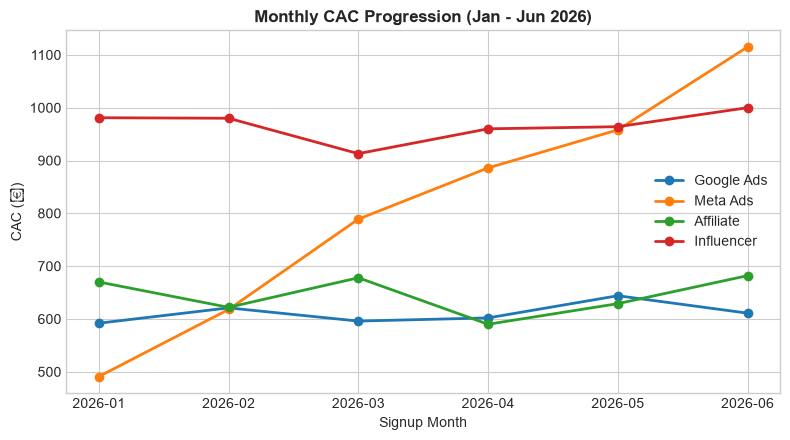

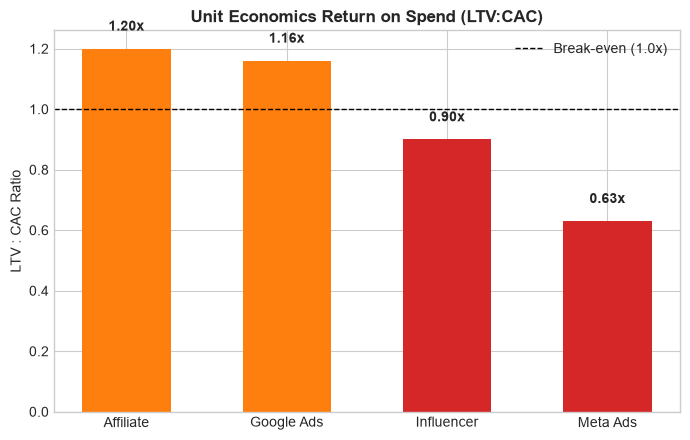

In [23]:
# Monthly new customers by signup month
monthly_cohorts = customer_df.groupby(['signup_month', 'acquisition_channel']).agg(
    monthly_new_customers=('user_id', 'count')
).reset_index()

# Monthly spend
monthly_spend_table = spend.rename(columns={'month': 'signup_month', 'channel': 'acquisition_channel'})

# Compute monthly CAC
monthly_cac_df = pd.merge(monthly_spend_table, monthly_cohorts, on=['signup_month', 'acquisition_channel'], how='left')
monthly_cac_df['monthly_cac'] = np.round(monthly_cac_df['spend_inr'] / monthly_cac_df['monthly_new_customers']).astype(int)

# Pivot table
cac_pivot = monthly_cac_df.pivot(index='acquisition_channel', columns='signup_month', values='monthly_cac')
first_m, last_m = cac_pivot.columns[0], cac_pivot.columns[-1]
cac_pivot['Change_INR'] = cac_pivot[last_m] - cac_pivot[first_m]
cac_pivot['Inflation_Pct'] = np.round((cac_pivot['Change_INR'] / cac_pivot[first_m]) * 100, 1)

print("=== Monthly CAC Trend & Inflation ===")
display(cac_pivot)

# Save Chart 1: Monthly CAC Progression
plt.figure(figsize=(8, 4.5))
for ch in monthly_cac_df['acquisition_channel'].unique():
    sub = monthly_cac_df[monthly_cac_df['acquisition_channel'] == ch].sort_values(by='signup_month')
    plt.plot(sub['signup_month'].astype(str), sub['monthly_cac'], marker='o', linewidth=2, label=ch)

plt.title("Monthly CAC Progression (Jan - Jun 2026)", fontsize=12, fontweight='bold')
plt.xlabel("Signup Month")
plt.ylabel("CAC (₹)")
plt.legend()
plt.tight_layout()
plt.savefig("charts/chart1_cac_trend.png", dpi=300)
plt.show()

# Save Chart 2: LTV vs CAC Comparison
plt.figure(figsize=(7, 4.5))
colors = ['#2ca02c' if x >= 1.5 else '#ff7f0e' if x >= 1.0 else '#d62728' for x in paid_only['ltv_to_cac']]
bars = plt.bar(paid_only['acquisition_channel'], paid_only['ltv_to_cac'], color=colors, width=0.55)
plt.axhline(1.0, color='black', linestyle='--', linewidth=1, label='Break-even (1.0x)')
plt.ylabel("LTV : CAC Ratio")
plt.title("Unit Economics Return on Spend (LTV:CAC)", fontsize=12, fontweight='bold')
for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 0.05, f"{y:.2f}x", ha='center', va='bottom', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig("charts/chart2_ltv_cac.png", dpi=300)
plt.show()

### 6. Sanity Check Verification
Reconcile total delivered order value against aggregated channel revenue to verify zero data loss.

In [24]:
method_1_rev = delivered_orders['order_value'].sum()
method_2_rev = perf_table['delivered_revenue'].sum()
discrepancy = abs(method_1_rev - method_2_rev)

print(f"Direct raw delivered order sum : ₹{method_1_rev:,.2f}")
print(f"Aggregated channel metric sum  : ₹{method_2_rev:,.2f}")
print(f"Discrepancy                   : ₹{discrepancy:,.2f}")

assert discrepancy < 1.0, f"Discrepancy remains: ₹{discrepancy:,.2f}"
print("Sanity Check Passed: 100% of delivered revenue reconciles across all cohorts without leakage.")

Direct raw delivered order sum : ₹5,945,268.00
Aggregated channel metric sum  : ₹5,945,268.00
Discrepancy                   : ₹0.00
Sanity Check Passed: 100% of delivered revenue reconciles across all cohorts without leakage.
